In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/enhanced_flight_data.csv")

df.head()

,Airline,Source,Destination,Total_Stops,Price,Journey_Day,Journey_Month,Journey_Weekday,Duration_Hours,Duration_Minutes,Festival,IPL,Days_Before
0,IndiGo,Banglore,New Delhi,0.0,3897,24,3,6.0,2,50,0,0,4
1,Air India,Kolkata,Banglore,2.0,7662,1,5,2.0,7,25,0,1,20
2,Jet Airways,Delhi,Cochin,2.0,13882,9,6,6.0,19,0,0,0,20
3,IndiGo,Kolkata,Banglore,1.0,6218,12,5,6.0,5,25,0,1,26
4,IndiGo,Banglore,New Delhi,1.0,13302,1,3,4.0,4,45,0,0,8


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50683 entries, 0 to 50682
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Airline           50683 non-null  object 
 1   Source            50683 non-null  object 
 2   Destination       50683 non-null  object 
 3   Total_Stops       50682 non-null  float64
 4   Price             50683 non-null  int64  
 5   Journey_Day       50683 non-null  int64  
 6   Journey_Month     50683 non-null  int64  
 7   Journey_Weekday   10683 non-null  float64
 8   Duration_Hours    50683 non-null  int64  
 9   Duration_Minutes  50683 non-null  int64  
 10  Festival          50683 non-null  int64  
 11  IPL               50683 non-null  int64  
 12  Days_Before       50683 non-null  int64  
dtypes: float64(2), int64(8), object(3)
memory usage: 5.0+ MB


In [3]:
df.describe()

,Total_Stops,Price,Journey_Day,Journey_Month,Journey_Weekday,Duration_Hours,Duration_Minutes,Festival,IPL,Days_Before
count,50682.000000,50683.000000,50683.000000,50683.000000,10683.000000,50683.000000,50683.000000,50683.000000,50683.000000,50683.000000
mean,0.957579,8596.581122,14.267309,6.126591,2.934850,4.918947,29.311130,0.132392,0.220942,15.458852
std,0.792578,2795.727900,8.180519,3.198138,2.006698,5.008322,17.226276,0.338919,0.414886,8.607685
min,0.000000,1759.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,6780.500000,7.000000,3.000000,1.000000,2.000000,15.000000,0.000000,0.000000,8.000000
50%,1.000000,8372.000000,14.000000,6.000000,3.000000,4.000000,30.000000,0.000000,0.000000,15.000000
75%,2.000000,10167.000000,21.000000,9.000000,5.000000,6.000000,45.000000,0.000000,0.000000,23.000000
max,4.000000,79512.000000,28.000000,12.000000,6.000000,47.000000,59.000000,1.000000,1.000000,30.000000


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")

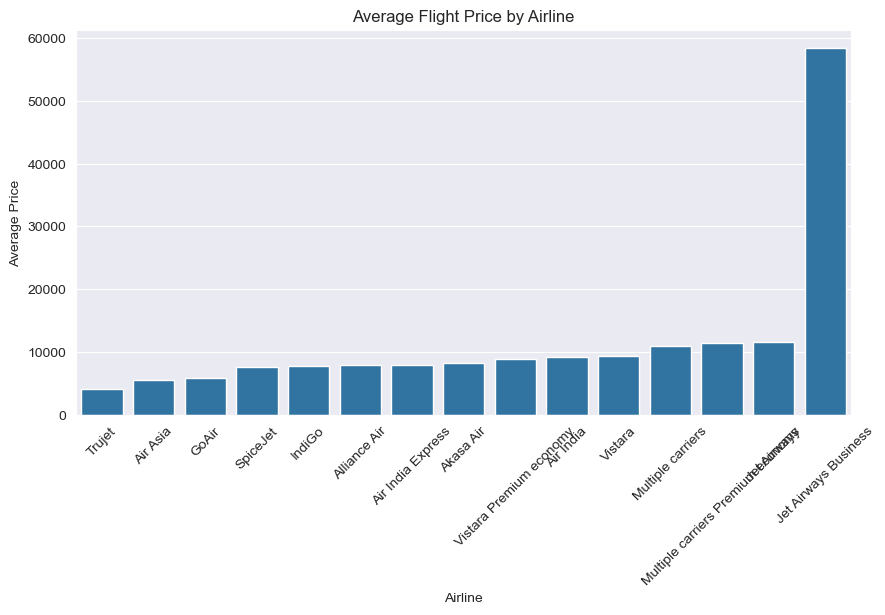

In [5]:
avg_price_airline = df.groupby("Airline")["Price"].mean().sort_values()

plt.figure(figsize=(10,5))
sns.barplot(x=avg_price_airline.index, y=avg_price_airline.values)

plt.title("Average Flight Price by Airline")
plt.xticks(rotation=45)
plt.ylabel("Average Price")
plt.show()

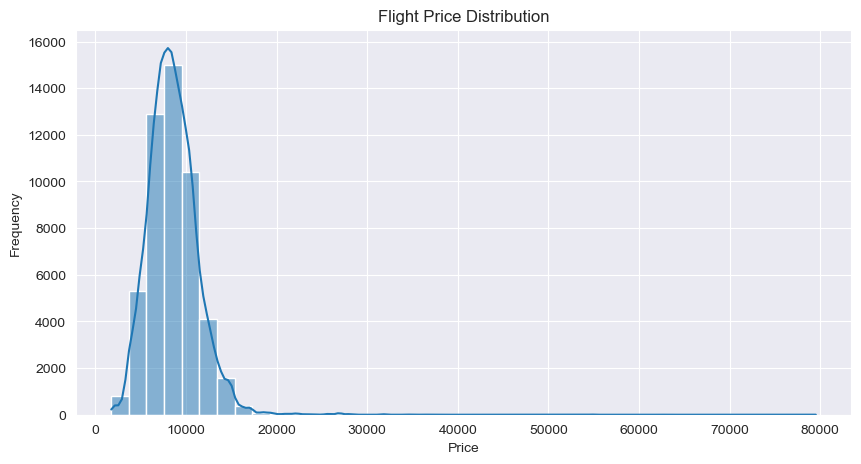

In [6]:
plt.figure(figsize=(10,5))
sns.histplot(df["Price"], bins=40, kde=True)

plt.title("Flight Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

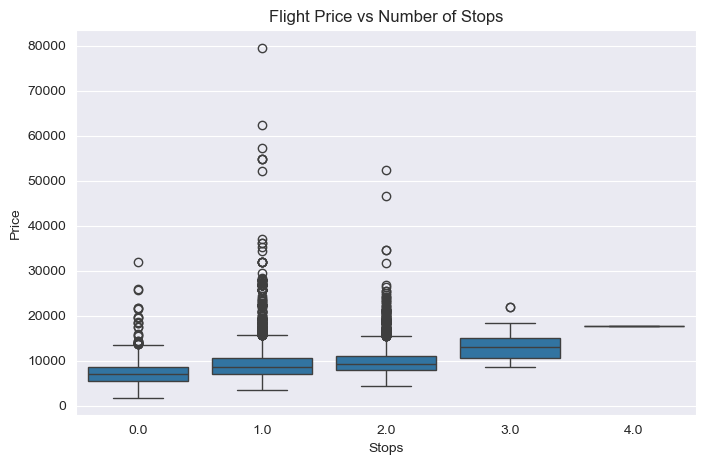

In [7]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["Total_Stops"], y=df["Price"])

plt.title("Flight Price vs Number of Stops")
plt.xlabel("Stops")
plt.ylabel("Price")

plt.show()

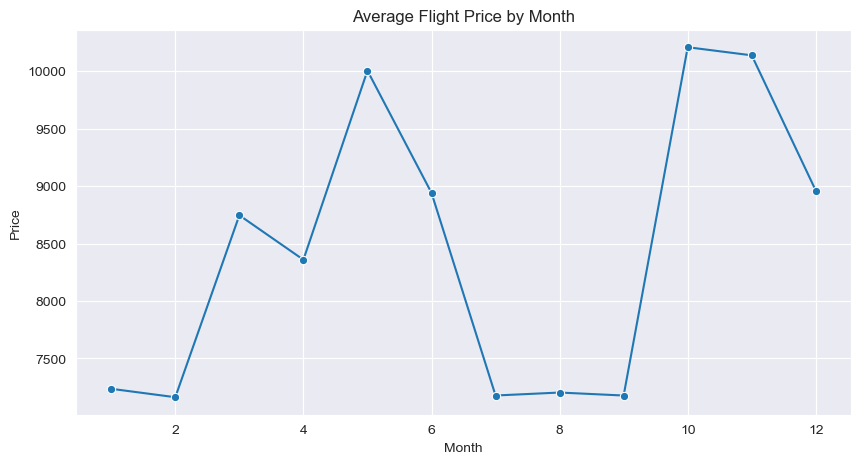

In [8]:
monthly_price = df.groupby("Journey_Month")["Price"].mean()

plt.figure(figsize=(10,5))
sns.lineplot(x=monthly_price.index, y=monthly_price.values, marker="o")

plt.title("Average Flight Price by Month")
plt.xlabel("Month")
plt.ylabel("Price")

plt.show()

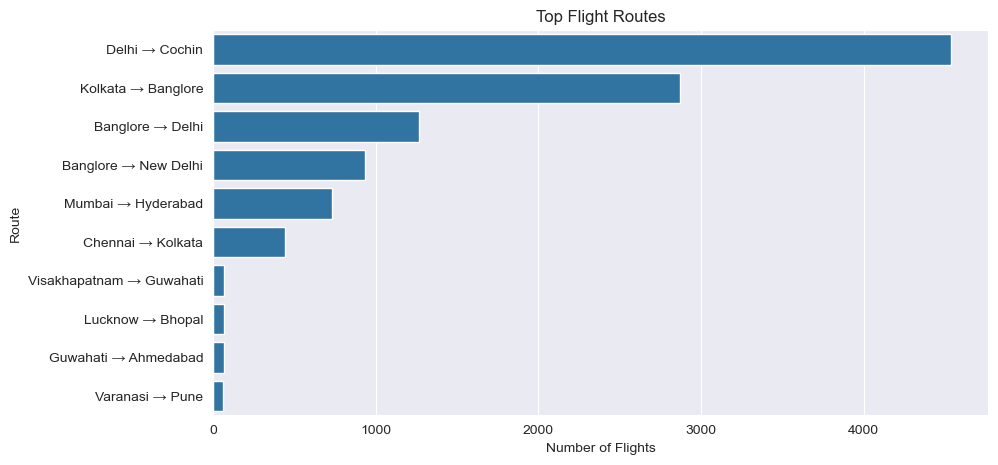

In [9]:
df["Route"] = df["Source"] + " → " + df["Destination"]

top_routes = df["Route"].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_routes.values, y=top_routes.index)

plt.title("Top Flight Routes")
plt.xlabel("Number of Flights")
plt.ylabel("Route")

plt.show()

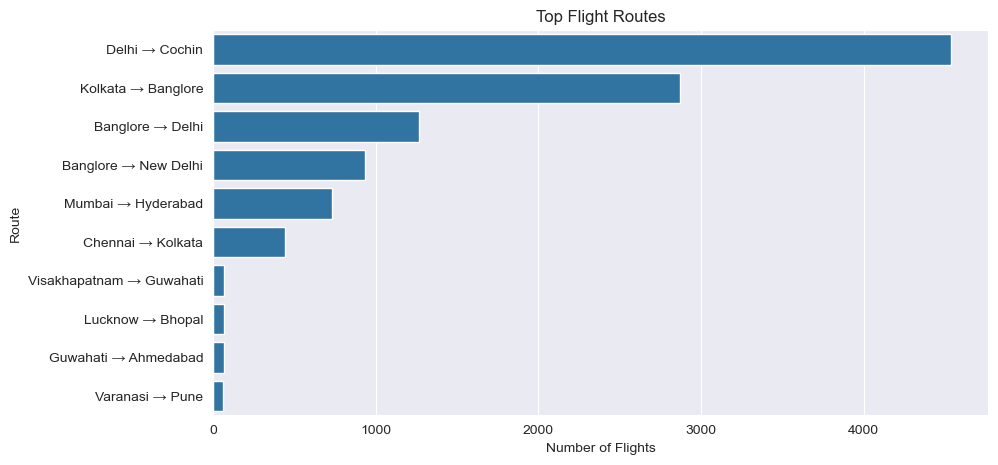

In [10]:
df["Route"] = df["Source"] + " → " + df["Destination"]

top_routes = df["Route"].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_routes.values, y=top_routes.index)

plt.title("Top Flight Routes")
plt.xlabel("Number of Flights")
plt.ylabel("Route")

plt.show()

In [11]:
festival_price = df.groupby("Festival")["Price"].mean()

festival_price

Festival
0     8355.777750
1    10174.650671
Name: Price, dtype: float64

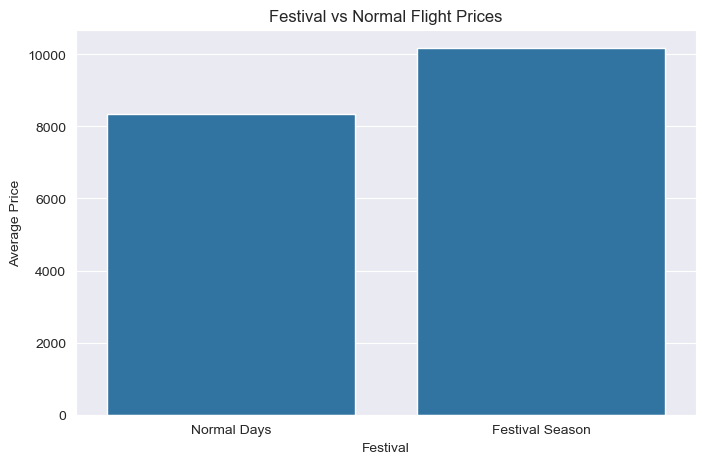

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.barplot(
    x=festival_price.index,
    y=festival_price.values
)

plt.title("Festival vs Normal Flight Prices")
plt.xticks([0,1], ["Normal Days", "Festival Season"])
plt.ylabel("Average Price")

plt.show()

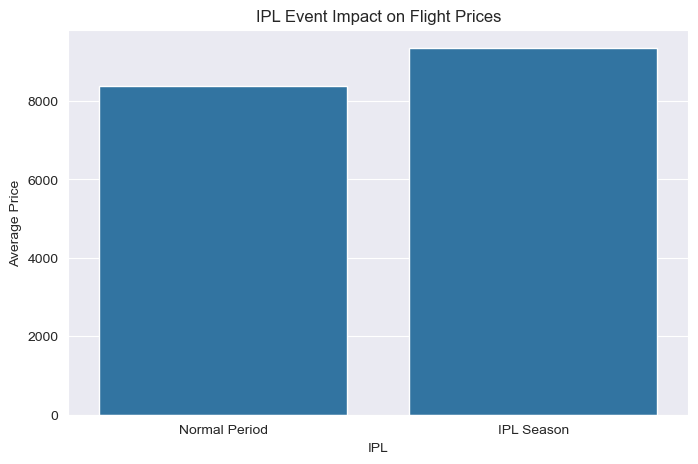

In [13]:
ipl_price = df.groupby("IPL")["Price"].mean()

plt.figure(figsize=(8,5))

sns.barplot(
    x=ipl_price.index,
    y=ipl_price.values
)

plt.title("IPL Event Impact on Flight Prices")
plt.xticks([0,1], ["Normal Period", "IPL Season"])
plt.ylabel("Average Price")

plt.show()

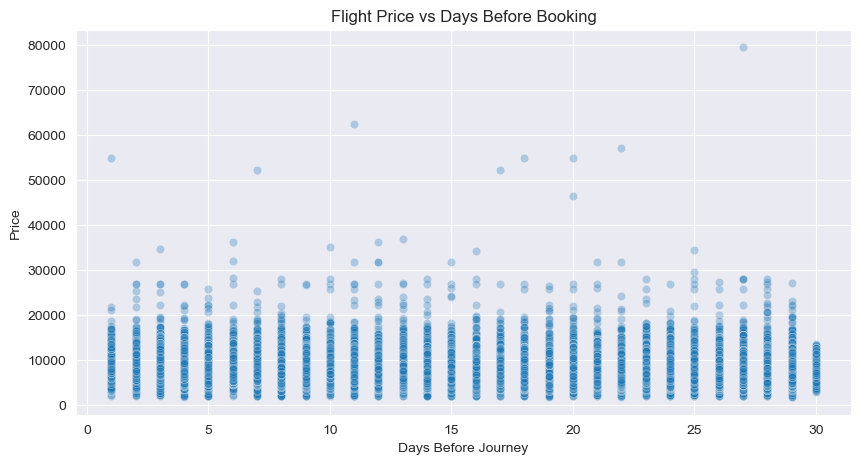

In [14]:
plt.figure(figsize=(10,5))

sns.scatterplot(
    x=df["Days_Before"],
    y=df["Price"],
    alpha=0.3
)

plt.title("Flight Price vs Days Before Booking")
plt.xlabel("Days Before Journey")
plt.ylabel("Price")

plt.show()

In [15]:
df["Route"] = df["Source"] + " → " + df["Destination"]

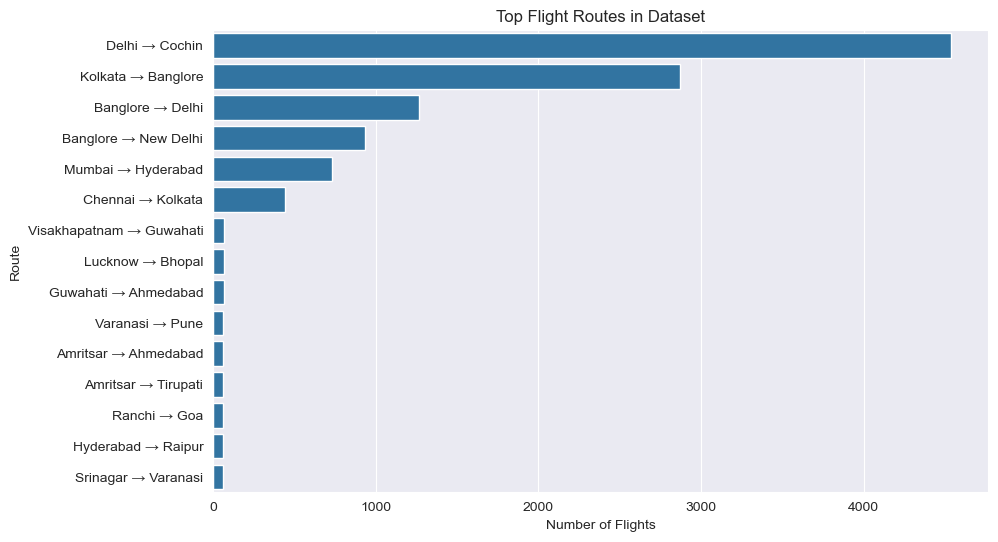

In [16]:
top_routes = df["Route"].value_counts().head(15)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_routes.values,
    y=top_routes.index
)

plt.title("Top Flight Routes in Dataset")
plt.xlabel("Number of Flights")
plt.ylabel("Route")

plt.show()

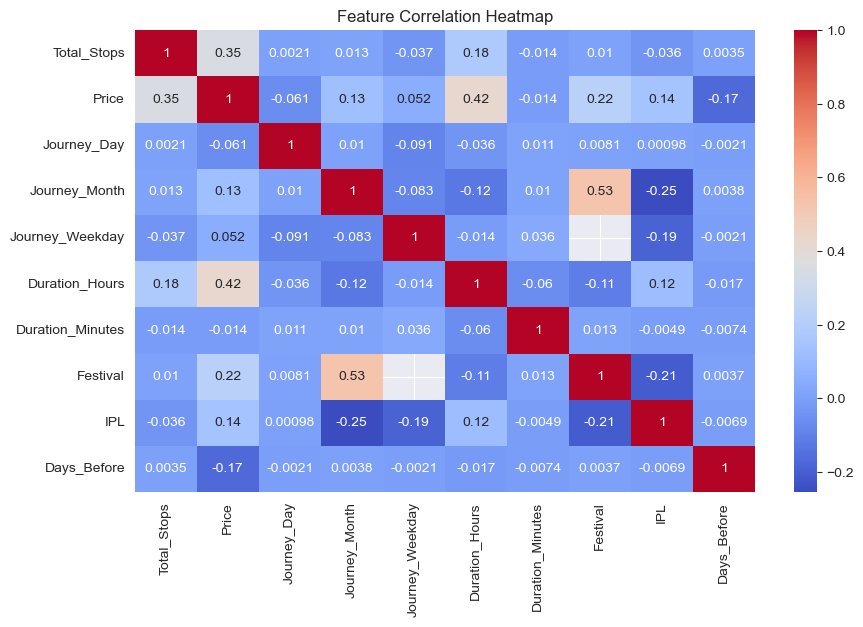

In [17]:
plt.figure(figsize=(10,6))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")

plt.show()

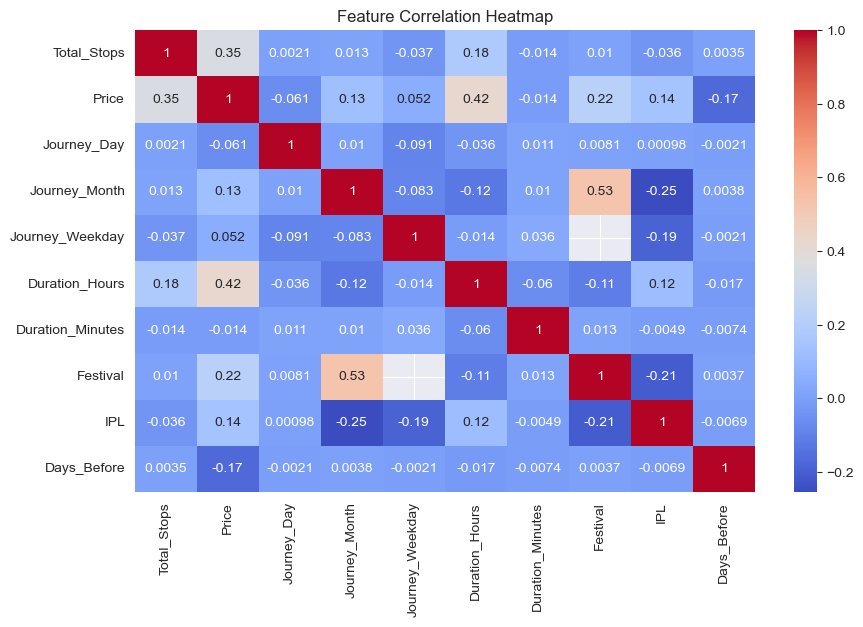

In [18]:
plt.figure(figsize=(10,6))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [19]:
import plotly.express as px
import plotly.graph_objects as go

In [20]:
airline_avg = df.groupby("Airline")["Price"].mean().reset_index()

fig = px.bar(
    airline_avg,
    x="Airline",
    y="Price",
    color="Airline",
    title="Average Flight Price by Airline",
)

fig.show()

In [21]:
monthly_price = df.groupby("Journey_Month")["Price"].mean().reset_index()

fig = px.line(
    monthly_price,
    x="Journey_Month",
    y="Price",
    markers=True,
    title="Monthly Flight Price Trend"
)

fig.show()

In [22]:
df["Route"] = df["Source"] + " → " + df["Destination"]

In [23]:
route_count = df["Route"].value_counts().head(15).reset_index()
route_count.columns = ["Route", "Flights"]

fig = px.bar(
    route_count,
    x="Flights",
    y="Route",
    orientation="h",
    title="Top Flight Routes Demand"
)

fig.show()

In [24]:
fig = px.histogram(
    df,
    x="Price",
    nbins=50,
    title="Flight Price Distribution"
)

fig.show()

In [25]:
fig = px.box(
    df,
    x="Total_Stops",
    y="Price",
    title="Flight Price vs Stops"
)

fig.show()

In [26]:
df = pd.read_csv("../data/big_flight_dataset.csv")

In [27]:
route_counts = df.groupby(["Source","Destination"]).size().reset_index(name="Flights")

route_counts = route_counts.sort_values(by="Flights", ascending=False)

route_counts.head(10)

,Source,Destination,Flights
240,Delhi,Cochin,4537
412,Kolkata,Banglore,2871
87,Banglore,Delhi,1265
88,Banglore,New Delhi,932
537,Mumbai,Hyderabad,900
160,Chennai,Kolkata,591
321,Guwahati,Visakhapatnam,252
339,Hyderabad,Mumbai,250
303,Guwahati,Hyderabad,250
837,Varanasi,Pune,249


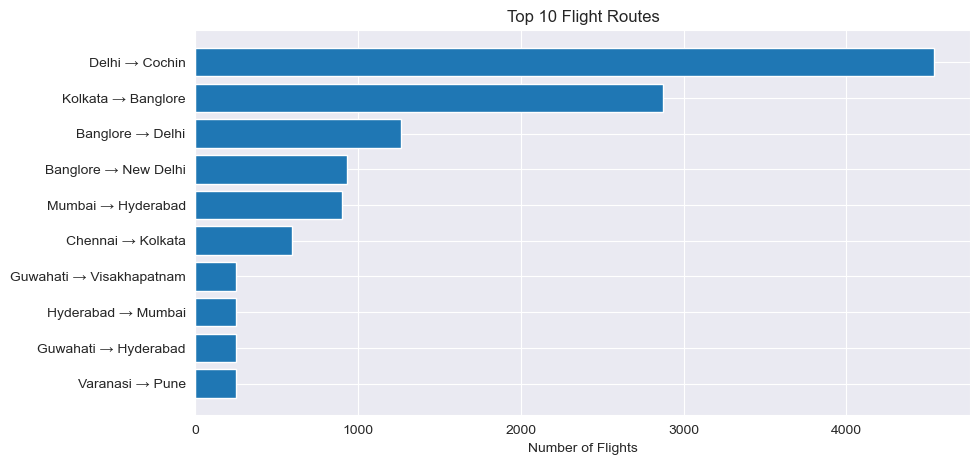

In [28]:
import matplotlib.pyplot as plt

top_routes = route_counts.head(10)

plt.figure(figsize=(10,5))

plt.barh(
    top_routes["Source"] + " → " + top_routes["Destination"],
    top_routes["Flights"]
)

plt.xlabel("Number of Flights")
plt.title("Top 10 Flight Routes")
plt.gca().invert_yaxis()

plt.show()

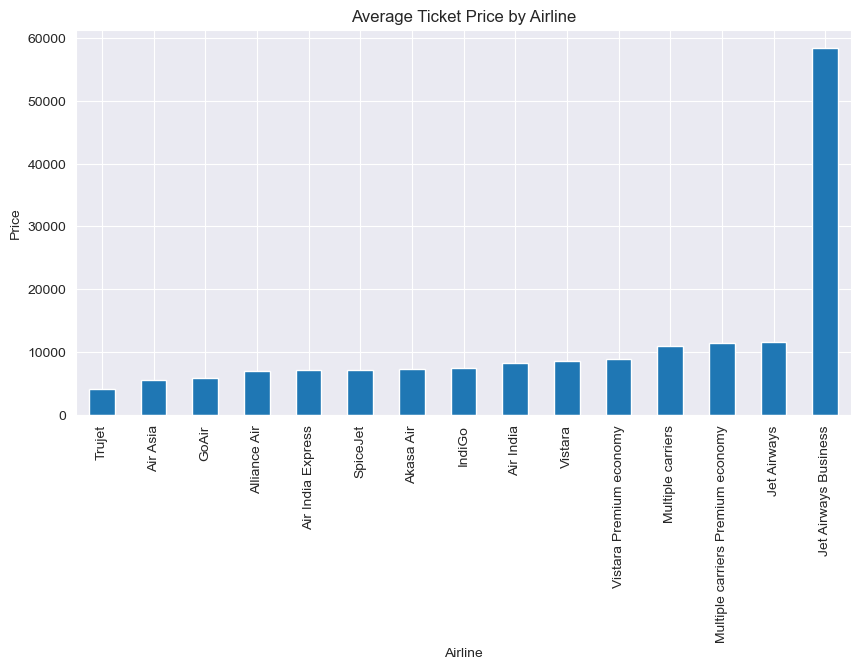

In [29]:
airline_price = df.groupby("Airline")["Price"].mean().sort_values()

plt.figure(figsize=(10,5))

airline_price.plot(kind="bar")

plt.title("Average Ticket Price by Airline")
plt.ylabel("Price")

plt.show()

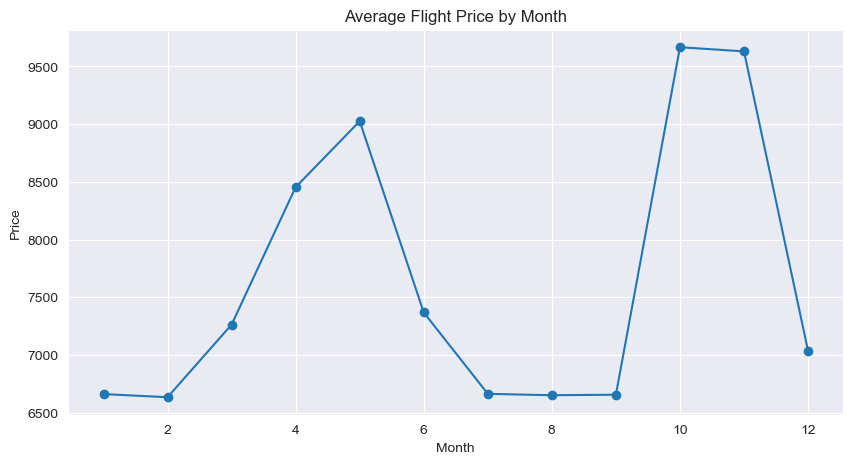

In [30]:
monthly_price = df.groupby("Journey_Month")["Price"].mean()

plt.figure(figsize=(10,5))

monthly_price.plot(marker='o')

plt.title("Average Flight Price by Month")
plt.xlabel("Month")
plt.ylabel("Price")

plt.show()

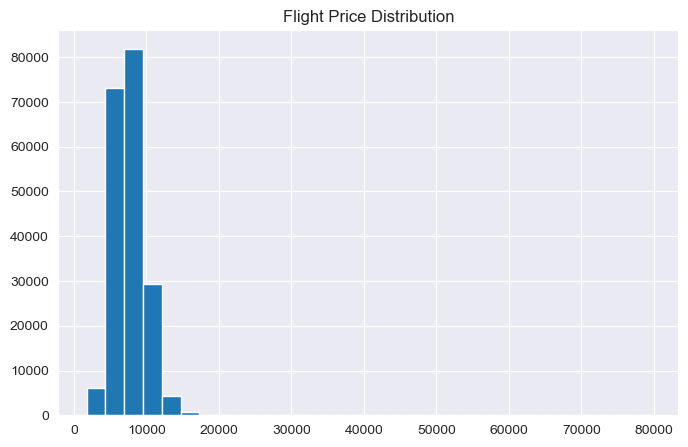

In [31]:
plt.figure(figsize=(8,5))

plt.hist(df["Price"], bins=30)

plt.title("Flight Price Distribution")

plt.show()

In [33]:
import pandas as pd

df = pd.read_csv("../data/enhanced_flight_data.csv")

cities = sorted(set(df["Source"]).union(set(df["Destination"])))

print(cities)

['Ahmedabad', 'Amritsar', 'Bangalore', 'Banglore', 'Bhopal', 'Chandigarh', 'Chennai', 'Cochin', 'Coimbatore', 'Dehradun', 'Delhi', 'Goa', 'Guwahati', 'Hyderabad', 'Indore', 'Jaipur', 'Kolkata', 'Lucknow', 'Madurai', 'Mangalore', 'Mumbai', 'Nagpur', 'New Delhi', 'Patna', 'Pune', 'Raipur', 'Ranchi', 'Srinagar', 'Surat', 'Tirupati', 'Vadodara', 'Varanasi', 'Visakhapatnam']


In [34]:
import os
os.getcwd()

'c:\\Users\\sai teja\\OneDrive\\Desktop\\AIRLINK\\analysis'